In [1]:
import pandas as pd

In [329]:
result_path = "./results/cdcp/"
path_minimal = "./dataset_minimal/"

### Component

In [330]:
# Cargar el CSV
dfv_train = pd.read_csv(path_minimal + "component_train.csv")
dfv_test = pd.read_csv(path_minimal + "component_test.csv")
dfv_value = pd.read_csv(path_minimal + "component_val.csv")

In [331]:
# Misturamos todo
dfc = pd.concat(
    [dfv_train, dfv_test, dfv_value],
    ignore_index=True
)
# dfc.shape

In [334]:
# Revisar os componentes por text_id
columna = "text_id"
df_filter = dfc[dfc[columna] == "CDCP_810"]
# print(df_filter.shape)
# df_filter

In [335]:
conteo = (
    dfc[columna]
    .drop_duplicates()
    .str.rsplit("_", n=1).str[0]
    .value_counts()
    .reset_index()
)

conteo.columns = ["valor", "cantidad"]

conteo["porcentaje"] = (
    conteo["cantidad"] / len(dfc[columna].drop_duplicates()) * 100
).round(2)

conteo

,valor,cantidad,porcentaje
0,CDCP,731,25.32
1,AbstRCT_neoplasm,500,17.32
2,Araucaria,448,15.52
3,AAEC,402,13.92
4,IBM_CE,293,10.15
5,ArGPT,172,5.96
6,MTC,112,3.88
7,AbstRCT_glaucoma,100,3.46
8,AbstRCT_mixed,69,2.39
9,AASD,60,2.08


In [344]:
indice_tableta_dataset = 0
name_dataset = conteo["valor"][indice_tableta_dataset]

# Só ids dos componentes
dfc_name_dataset = dfc[dfc[columna].str.contains(name_dataset, na=False)].copy()
dfc_name_dataset_summary = (
    dfc_name_dataset.groupby(columna)
       .size()
       .reset_index(name="nós")
)

print(dfc_name_dataset_summary.shape)
dfc_name_dataset_summary

(731, 2)


,text_id,nós
0,CDCP_1000,5
1,CDCP_1001,10
2,CDCP_1002,9
3,CDCP_1005,6
4,CDCP_1006,2
...,...,...
726,CDCP_995,12
727,CDCP_996,9
728,CDCP_997,9
729,CDCP_998,6


In [265]:
def get_nodes(text_id):
    dfc_resultado_component = dfc[dfc[columna].str.contains(text_id, na=False)].copy()
    dfc_resultado_component.insert(
        0,
        "component_id",
        range(0, len(dfc_resultado_component))
    )
    return dfc_resultado_component

### Relation

In [337]:
# Cargar el CSV
dfr_train = pd.read_csv(path_minimal + "relation_train.csv")
dfr_test = pd.read_csv(path_minimal + "relation_test.csv")
dfr_val = pd.read_csv(path_minimal + "relation_val.csv")
dfr = pd.concat(
    [dfr_train, dfr_test, dfr_val],
    ignore_index=True
)
# dfr.shape

In [338]:
# Revisar as relações por text_id
df_filter = dfr[dfr[columna] == "CDCP_817"]
print(df_filter.shape)
df_filter

(4, 6)


,Unnamed: 0,text_id,source_tokens,target_tokens,labels,minimalist_labels
1433,1436,CDCP_817,Disputability of any amount over the amount at...,If you want to instantly level the playing fie...,reason,support
1434,1437,CDCP_817,"As it stands now, credit card companies can an...",Disputability of any amount over the amount at...,reason,support
1435,1438,CDCP_817,as they rack up frequent default points on the...,Disputability of any amount over the amount at...,reason,support
1436,1439,CDCP_817,as they rack up frequent default points on the...,and may even let the account stay in default,reason,support


In [339]:
def get_edges(text_id):
    dfr_resultado_relation = dfr[dfr[columna] == text_id]
    dfr_resultado_relation = dfr_resultado_relation.dropna()
    return dfr_resultado_relation

### Build graph

In [257]:
# Preparar dfc_resultado_component con solo las columnas necesarias
def get_data_graph(dfc_resultado_component, dfr_resultado_relation):
    df_component = dfc_resultado_component[["component_id","component_tokens", "labels", "minimalist_labels"]].copy()

    # Merge para obtener labels del SOURCE
    df_merged = dfr_resultado_relation.merge(
        df_component.rename(columns={
            "component_id": "source_id",
            "component_tokens": "source_tokens",
            "labels": "label_component_source",
            "minimalist_labels": "minimal_label_component_source"
        }),
        on="source_tokens",
        how="left"
    )

    # Merge para obtener labels del TARGET
    df_merged = df_merged.merge(
        df_component.rename(columns={
            "component_id": "target_id",
            "component_tokens": "target_tokens",
            "labels": "label_component_target",
            "minimalist_labels": "minimal_label_component_target"
        }),
        on="target_tokens",
        how="left"
    )

    # Renombrar labels de la relación
    df_merged = df_merged.rename(columns={"labels": "labels_relation"})

    # Seleccionar solo las columnas que necesitas
    df_nuevo = df_merged[[
        "minimalist_labels",
        "labels_relation",
        "source_id",
        "label_component_source",
        "minimal_label_component_source",
        "target_id",
        "label_component_target",
        "minimal_label_component_target"
    ]]

    return df_nuevo

In [258]:
def crear_grafo(df_sub):  
    # Crear grafo dirigido
    G = nx.DiGraph()
    
    for _, row in df_sub.iterrows():
        G.add_edge(row["source_id"], row["target_id"], label=row["minimalist_labels"])
        G.nodes[row["source_id"]]["component"] = row["minimal_label_component_source"]
        G.nodes[row["target_id"]]["component"] = row["minimal_label_component_target"]

    n_comp = nx.number_weakly_connected_components(G)
    n_isolates = nx.number_of_isolates(G)
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()
    return G, n_nodes, n_edges, n_comp, n_isolates

def plot_grafo(text_id, G):
    # Cor por nó
    color_nodo = {
        "MajorClaim" : "#e74c3c",   # Vermelho
        "Claim"      : "#3498db",   # Azul
        "Premise"    : "#2ecc71",   # Verde
    }
    node_colors = [
        color_nodo.get(G.nodes[n].get("component", ""), "#95a5a6")
        for n in G.nodes()
    ]

    colores_label = {
        "support" : "#27ae60",   # Verde oscuro
        "attacks"  : "#c0392b",   # Vermelho oscuro
    }
    edge_colors   = [colores_label.get(d["label"], "gray") for _, _, d in G.edges(data=True)]
    
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(G, seed=42, k=3, iterations=100)
    
    # Etiquetas de nodos con ID + tipo de componente
    node_labels = {
        n: f"{n}\n{G.nodes[n].get('component', '')}"
        for n in G.nodes()
    }

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2000)
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_color="black", font_size=8, font_weight="bold")
    nx.draw_networkx_edges(
        G, pos,
        edge_color=edge_colors,
        arrows=True, arrowsize=25, arrowstyle="-|>",
        width=2, connectionstyle="arc3,rad=0.1",
        min_source_margin=30, min_target_margin=30,
    )
    
    edge_labels = nx.get_edge_attributes(G, "label")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7, font_color="darkgreen")
    
    from matplotlib.lines import Line2D
    leyenda = [
        Line2D([0], [0], color="green", linewidth=2, label="support"),
        Line2D([0], [0], color="red",   linewidth=2, label="attacks"),
        Line2D([0], [0], color="gray",  linewidth=2, label="otros"),
    ]
    plt.legend(handles=leyenda, loc="upper left", fontsize=9)
    plt.title(f"Grafo argumentativo: {text_id}", fontsize=14)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### Preparate info to graph

In [267]:
info = "info"
g = "graph"
n_node = "n_nodes"
n_edge = "n_edges"
n_comp = "n_comp"
n_isol = "n_isolates"

dfc_name_dataset_summary[info] = None
dfc_name_dataset_summary[g] = None
dfc_name_dataset_summary[n_node] = None
dfc_name_dataset_summary[n_edge] = None
dfc_name_dataset_summary[n_comp] = None
dfc_name_dataset_summary[n_isol] = None


for idx, component_id in dfc_name_dataset_summary[columna].items():
    df_nodes = get_nodes(component_id)
    df_edges = get_edges(component_id)
    df_graph = get_data_graph(df_nodes, df_edges)
    graph, n_nodes, n_edges, n_compt, n_isolates = crear_grafo(df_graph)
    dfc_name_dataset_summary.at[idx, info] = df_graph
    dfc_name_dataset_summary.at[idx, g] = graph
    dfc_name_dataset_summary.at[idx, n_node] = n_nodes
    dfc_name_dataset_summary.at[idx, n_edge] = n_edges
    dfc_name_dataset_summary.at[idx, n_comp] = n_compt
    dfc_name_dataset_summary.at[idx, n_isol] = n_isolates

In [325]:
id_text_busca = "CDCP_817"
dfc_name_dataset_summary.to_csv(result_path + "CDCP_Minimal_Grafo.csv", index=False)
result = dfc_name_dataset_summary[dfc_name_dataset_summary[columna] == id_text_busca]
result

,text_id,nós,info,graph,n_nodes,n_edges,n_comp,n_isolates
645,CDCP_817,11,minimalist_labels labels_relation source_id...,"(1, 0, 2, 4, 3)",5,4,1,0


In [326]:
result_info = result.iloc[0]
result_info["info"]

,minimalist_labels,labels_relation,source_id,label_component_source,minimal_label_component_source,target_id,label_component_target,minimal_label_component_target
0,support,reason,1,value,MajorClaim,0,policy,MajorClaim
1,support,reason,2,fact,Premise,1,value,MajorClaim
2,support,reason,4,value,MajorClaim,1,value,MajorClaim
3,support,reason,4,value,MajorClaim,3,value,MajorClaim


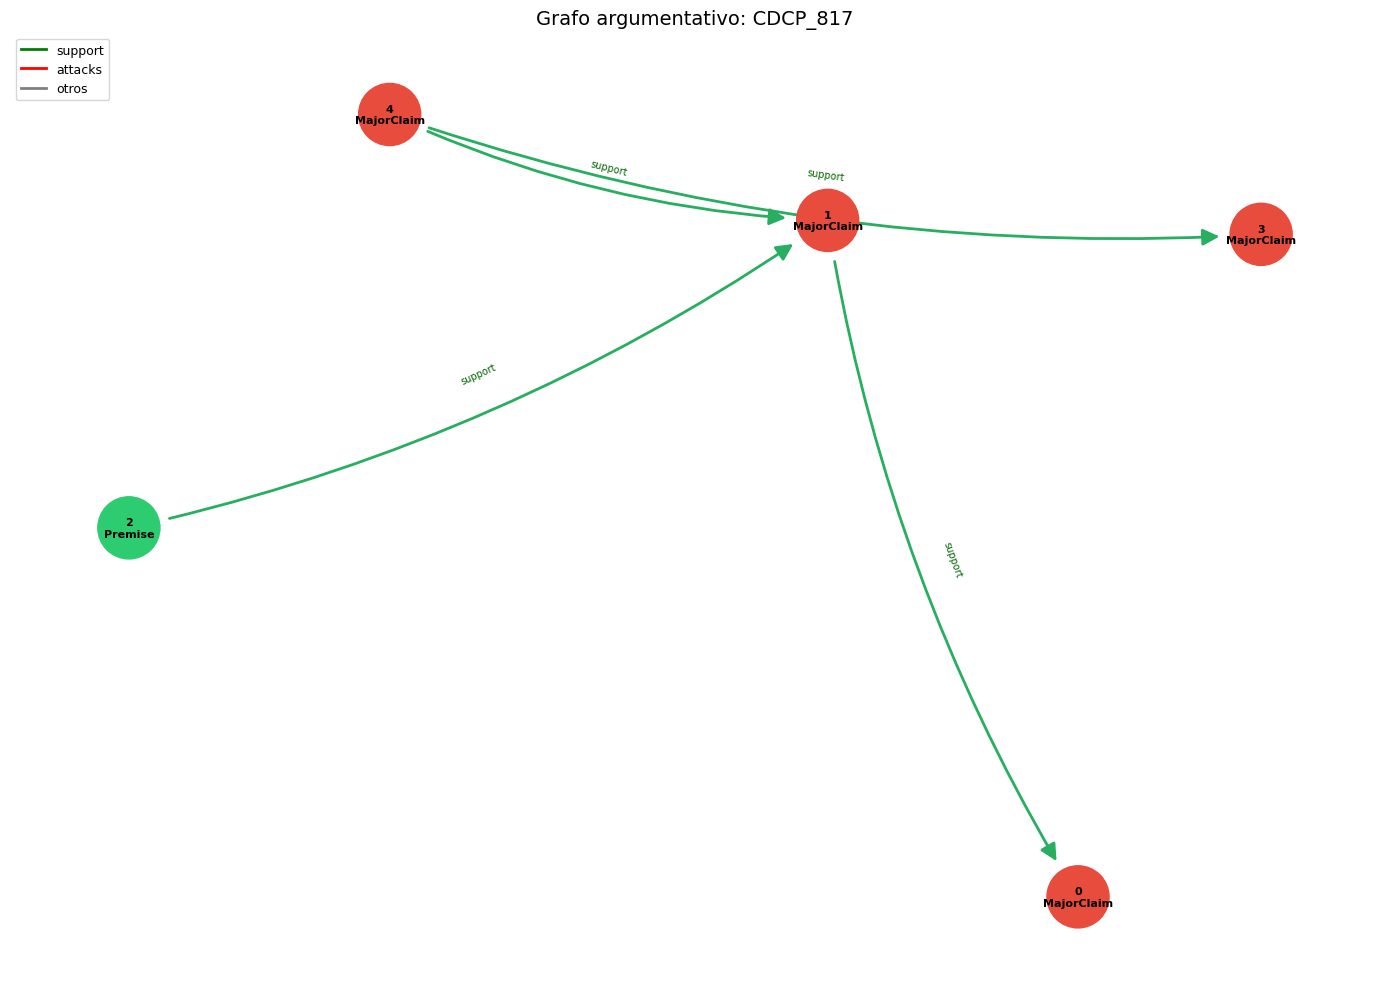

In [327]:
plot_grafo(id_text_busca, result_info["graph"])